# R4 — Neural Network Model Comparison (BloodMNIST)

Compares three neural architectures on the **same held-out test split** of BloodMNIST:

| Model | Type | Input |
|---|---|---|
| Custom MLP | Trained from scratch | 32×32×3 (3,072 flattened features) |
| ResNet50 | Transfer learning, frozen backbone | 128×128×3 |
| EfficientNetB5 | Transfer learning, frozen backbone | 128×128×3 |

All models are evaluated on identical test labels. `shuffle=False` is enforced everywhere so
predictions stay aligned with ground truth.

Metrics: **accuracy** and **macro F1** (macro F1 is the primary metric because BloodMNIST is
class-imbalanced), plus per-class F1 and confusion matrices.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Paths (notebook lives in notebooks/)
ROOT = Path("..").resolve()
DATA_PATH = ROOT / "data" / "raw" / "bloodmnist_128.npz"
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Load the test split

The `.npz` already contains a fixed train/val/test split, so no re-splitting is done here.
Only the test split is loaded - validation was used during training for early stopping.

In [ ]:
data = np.load(DATA_PATH)

TEST = data["test_images"]
y_test = data["test_labels"].ravel().astype(int)

CLASS_NAMES = [
    "basophil", "eosinophil", "erythroblast", "immature granulocyte",
    "lymphocyte", "monocyte", "neutrophil", "platelet",
]
N_CLASSES = len(CLASS_NAMES)

print("Test images:", TEST.shape, TEST.dtype)
print("Test labels:", y_test.shape)
print("Pixel range:", TEST.min(), "-", TEST.max())
print("Class counts:", np.bincount(y_test, minlength=N_CLASSES))

Test images: (3421, 128, 128, 3) uint8
Test labels: (3421,)
Pixel range: 2 - 255
Class counts: [244 624 311 579 243 284 666 470]


## Per-model preprocessing

This is the part that differs from the tabular comparison notebook. Each architecture was
trained with its own preprocessing, so evaluation must reproduce it exactly:

- **MLP** — trained on pixels scaled to `[0, 1]`, resized to 32×32.
- **ResNet50** — `resnet50.preprocess_input` (RGB→BGR, ImageNet mean subtraction), expects 0–255.
- **EfficientNetB5** — `efficientnet.preprocess_input` is a pass-through in `tf.keras`
  (normalisation happens inside the model), so raw 0–255 is correct.

Feeding the wrong preprocessing to a pretrained backbone gives artificially bad scores.

In [3]:
MODEL_SPECS = {
    "MLP": {
        "path": MODELS_DIR / "MLP_custom.keras",
        "img_size": 32,
        "preprocess": lambda x: x / 255.0,
    },
    "ResNet50": {
        "path": MODELS_DIR / "ResNet50_tl.keras",
        "img_size": 128,
        "preprocess": resnet_preprocess,
    },
    "EfficientNetB5": {
        "path": MODELS_DIR / "EfficentNetB5_tl.keras",
        "img_size": 128,
        "preprocess": efficientnet_preprocess,
    },
}

missing = [name for name, s in MODEL_SPECS.items() if not s["path"].exists()]
if missing:
    raise FileNotFoundError(
        f"Missing saved models: {missing}\n"
        f"Run the corresponding training script in scripts/ first, "
        f"or fix the filenames in MODEL_SPECS."
    )

for name, spec in MODEL_SPECS.items():
    print(f"{name:16s} <- {spec['path'].name}  (input {spec['img_size']}x{spec['img_size']})")

MLP              <- MLP_custom.keras  (input 32x32)
ResNet50         <- ResNet50_tl.keras  (input 128x128)
EfficientNetB5   <- EfficentNetB5_tl.keras  (input 128x128)


In [4]:
def prepare_images(images, img_size):
    """Resize only if needed, and return float32."""
    if images.shape[1] != img_size or images.shape[2] != img_size:
        images = tf.image.resize(images, (img_size, img_size)).numpy()
    return images.astype("float32")


def predict_model(model, images, preprocess, batch_size=32):
    x = preprocess(images.copy())
    probs = model.predict(x, batch_size=batch_size, verbose=0)
    return np.argmax(probs, axis=1)

## Overall results

Accuracy and macro F1 on the identical test set, plus parameter counts for the
architecture-cost discussion in the report.

Saved training curves for MLP to /Users/nirup/git/F21DL-2026-27-UG-group-17/results/figures/MLP_training_curves.png
Saved training curves for ResNet50 to /Users/nirup/git/F21DL-2026-27-UG-group-17/results/figures/ResNet50_training_curves.png
Saved training curves for EfficientNetB5 to /Users/nirup/git/F21DL-2026-27-UG-group-17/results/figures/EfficientNetB5_training_curves.png


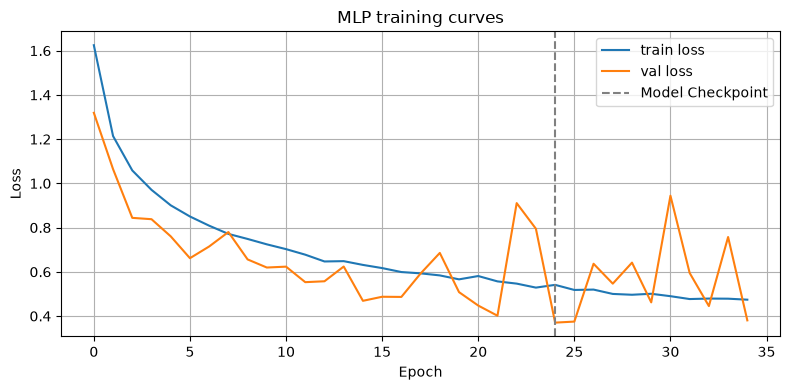

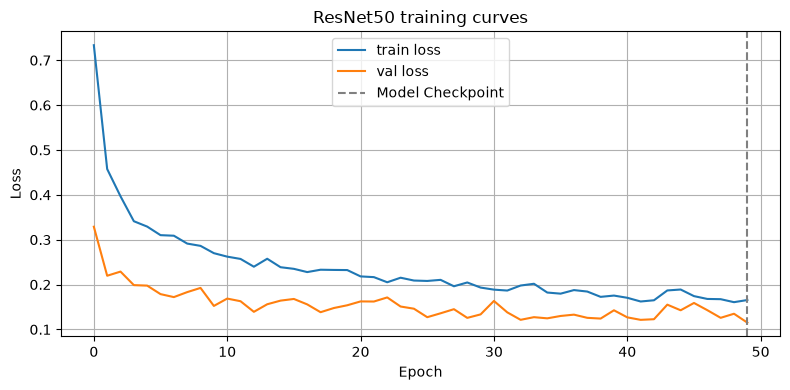

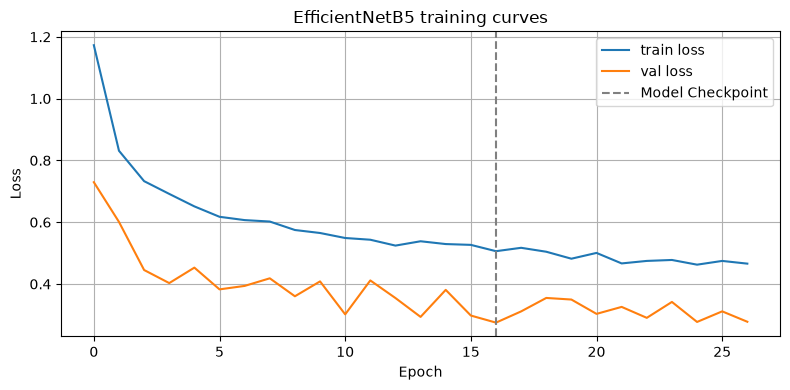

In [16]:
# learning curves (located in /results)
for name, spec in MODEL_SPECS.items():
    history_path = RESULTS_DIR / f"{name}_history.csv"
    if not history_path.exists():
        print(f"Skipping {name}: no history file {history_path}")
        continue
    history = pd.read_csv(history_path)
    plt.figure(figsize=(8, 4))
    plt.plot(history["loss"], label="train loss")
    plt.plot(history["val_loss"], label="val loss") 
    plt.axvline(x=history["val_loss"].idxmin(), color="gray", linestyle="--", label="Model Checkpoint")  
    plt.title(f"{name} training curves")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()
    plt.tight_layout()
    figure_path = FIGURES_DIR / f"{name}_training_curves.png"
    plt.savefig(figure_path)
    print(f"Saved training curves for {name} to {figure_path}")

In [6]:
predictions = {}
rows = []

for name, spec in MODEL_SPECS.items():
    model = tf.keras.models.load_model(spec["path"], compile=False)

    x_test = prepare_images(TEST, spec["img_size"])
    y_pred = predict_model(model, x_test, spec["preprocess"])
    predictions[name] = y_pred

    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))

    rows.append({
        "Model": name,
        "Input": f"{spec['img_size']}x{spec['img_size']}",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Total params": model.count_params(),
        "Trainable params": trainable,
    })

    tf.keras.backend.clear_session()

results = pd.DataFrame(rows).set_index("Model")
results.to_csv(RESULTS_DIR / "r4_overall_results.csv")

print(results.round(3).to_string())

                  Input  Accuracy  Macro F1  Total params  Trainable params
Model                                                                      
MLP               32x32     0.852     0.836       1741320           1739528
ResNet50        128x128     0.956     0.955      24114312            526600
EfficientNetB5  128x128     0.893     0.886      29040127            526600


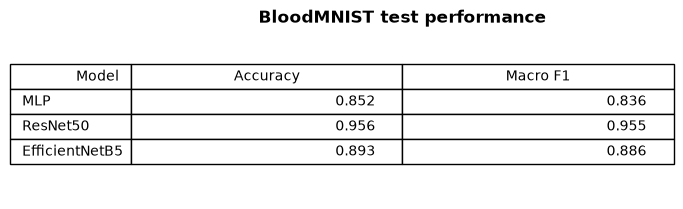

In [7]:
display_cols = ["Accuracy", "Macro F1"]
table_data = results[display_cols].round(3)

fig, ax = plt.subplots(figsize=(7, 2.2))
ax.axis("off")

table = ax.table(
    cellText=table_data.values,
    rowLabels=table_data.index,
    colLabels=table_data.columns,
    loc="center",
)
table.add_cell(0, -1, text="Model", width=0.2, height=table[0, 0].get_height())
table.scale(1, 1.5)
ax.set_title("BloodMNIST test performance", fontweight="bold", pad=5)

plt.savefig(FIGURES_DIR / "r4_overall_results.png", bbox_inches="tight", dpi=150)
plt.show()

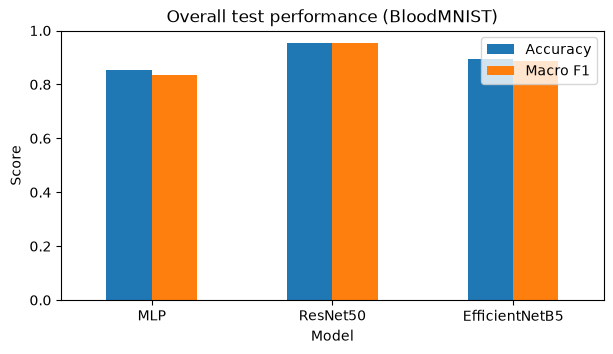

In [8]:
results[display_cols].plot.bar(rot=0, ylim=(0, 1), figsize=(7, 3.5),
                               title="Overall test performance (BloodMNIST)")
plt.ylabel("Score")
plt.savefig(FIGURES_DIR / "r4_compare_overall.png", dpi=150, bbox_inches="tight")
plt.show()

## Per-class F1

Overall scores hide minority-class failure. BloodMNIST is imbalanced, so a model can score
well on accuracy while failing on rare classes (e.g. basophil, eosinophil).

                        MLP  ResNet50  EfficientNetB5
basophil              0.684     0.948           0.871
eosinophil            0.955     0.979           0.923
erythroblast          0.876     0.966           0.913
immature granulocyte  0.683     0.909           0.826
lymphocyte            0.843     0.954           0.875
monocyte              0.732     0.936           0.782
neutrophil            0.920     0.952           0.914
platelet              0.996     0.996           0.984


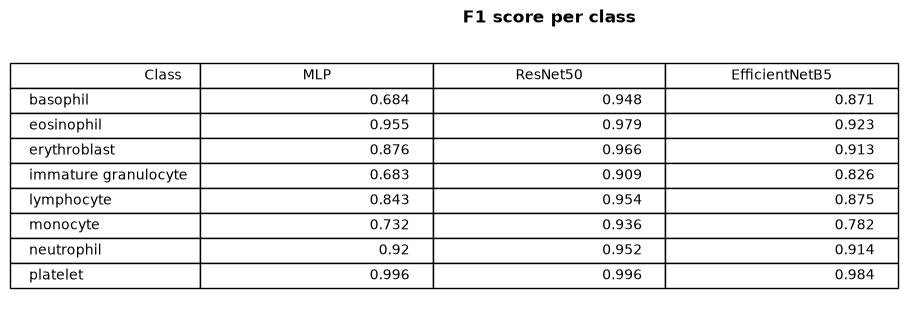

In [9]:
class_scores = {
    name: f1_score(y_test, y_pred, average=None, labels=range(N_CLASSES))
    for name, y_pred in predictions.items()
}

per_class = pd.DataFrame(class_scores, index=CLASS_NAMES)
per_class.to_csv(RESULTS_DIR / "r4_per_class_f1.csv")

print(per_class.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axis("off")

table = ax.table(
    cellText=per_class.round(3).values,
    rowLabels=per_class.index,
    colLabels=per_class.columns,
    loc="center",
)
table.add_cell(0, -1, text="Class", width=0.25, height=table[0, 0].get_height())
table.scale(1, 1.5)
ax.set_title("F1 score per class", fontweight="bold", pad=5)

plt.savefig(FIGURES_DIR / "r4_per_class_results.png", bbox_inches="tight", dpi=150)
plt.show()

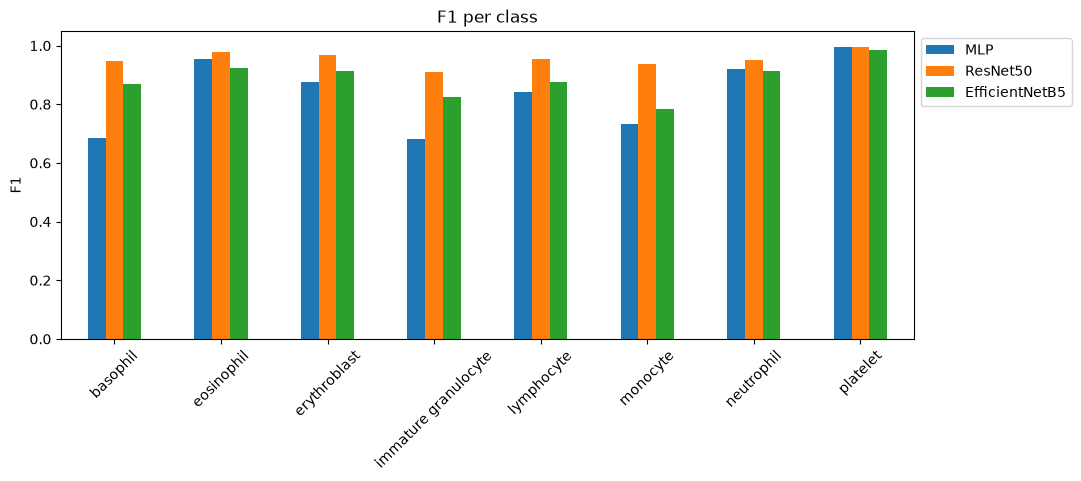

In [10]:
per_class.plot.bar(rot=45, ylim=(0, 1.05), figsize=(11, 4), title="F1 per class")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.ylabel("F1")
plt.savefig(FIGURES_DIR / "r4_compare_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

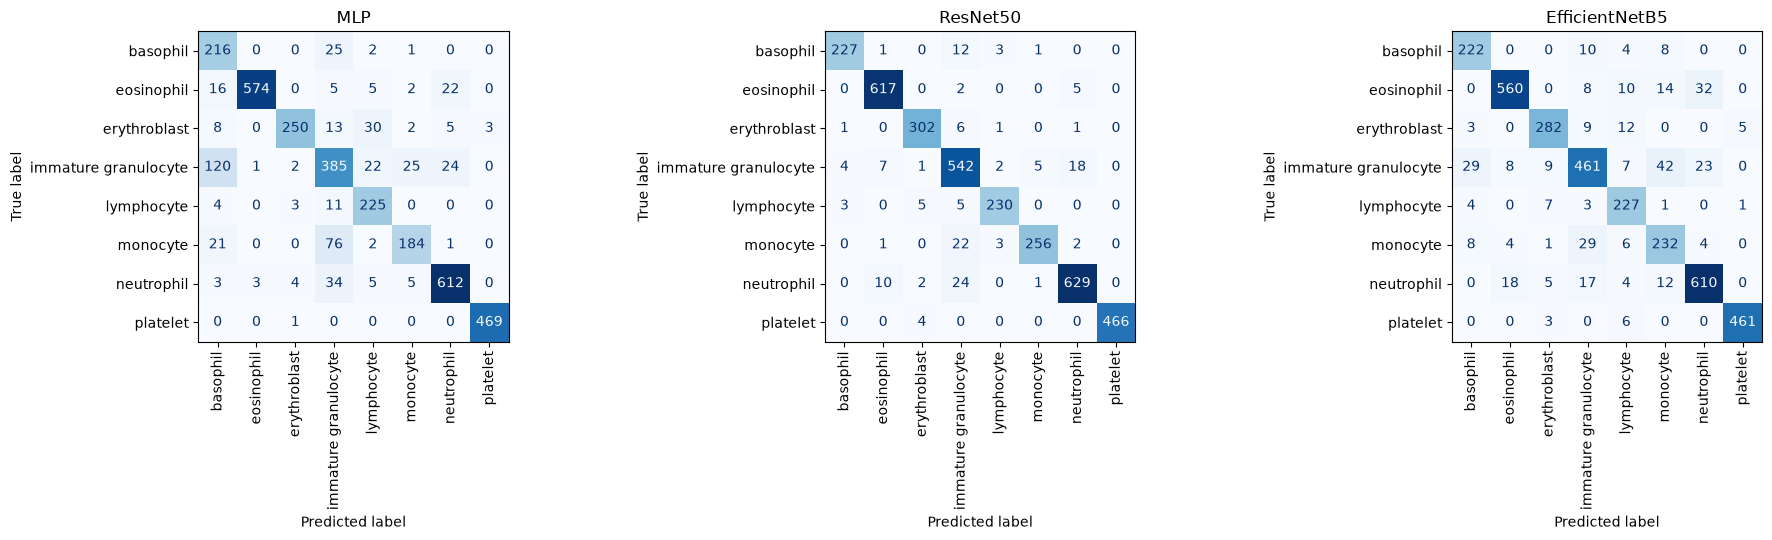

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=range(N_CLASSES),
        display_labels=CLASS_NAMES,
        ax=ax,
        cmap="Blues",
        xticks_rotation=90,
        colorbar=False,
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "r4_compare_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
for name, y_pred in predictions.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, y_pred,
                                labels=range(N_CLASSES),
                                target_names=CLASS_NAMES,
                                digits=3))

MLP
                      precision    recall  f1-score   support

            basophil      0.557     0.885     0.684       244
          eosinophil      0.993     0.920     0.955       624
        erythroblast      0.962     0.804     0.876       311
immature granulocyte      0.701     0.665     0.683       579
          lymphocyte      0.773     0.926     0.843       243
            monocyte      0.840     0.648     0.732       284
          neutrophil      0.922     0.919     0.920       666
            platelet      0.994     0.998     0.996       470

            accuracy                          0.852      3421
           macro avg      0.843     0.846     0.836      3421
        weighted avg      0.868     0.852     0.855      3421

ResNet50
                      precision    recall  f1-score   support

            basophil      0.966     0.930     0.948       244
          eosinophil      0.970     0.989     0.979       624
        erythroblast      0.962     0.971     0.966  